# Numerical Analysis

In [13]:
import numpy as np
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Math, Latex

In [3]:
#convention: do not define f(x) as a global function

## 1.1 Root-Finding
### Theorem 1.1.1
For a real-valued function $f$, continuous on bounded closed interval $[a, b] \epsilon \reals$:  
&emsp; if $f(a)f(b)<0$,  
&emsp; then there exsits $\tau \epsilon [a,b]$  
&emsp; such that $f(\tau)=0$  
  
Construct a series of estimates ${x_0, x_1, x_2,..., x_k}$ that converge on the true solution $\tau$  
Then show that $\lim_{k\to\infty} x_k = \tau$  
  
Let $\varepsilon_k$ be the bound on the error at step k:  $|\tau - x_k|<\varepsilon_k$>  
And because the method converges, the bound on the error is always decreasing: $|\tau-x_k|<|\tau-x_{k-1}>  
Then: \varepsilon_{k+1}<\mu\varepsilon_k$ for some number $\mu\epsilon(0,1)$

### Exercise 1.1.1
Does Theorem 1.1 mean that, if there is a solution to $f(x) = 0$ in $[a, b]$ then $f(a)f(b) \leq 0$? That is, is $f(a)f(b) \leq 0$ a necessary condition for there being a solution to $f(x) = 0$? Give an example that supports your answer.  
  
Meetng the condition implies there is a solution, does the existence of a solution imply meeting the condition? $A \implies B$, does $B \implies A$?  
Answer: no

In [4]:
def f1(x):
    return -x**2 + 3

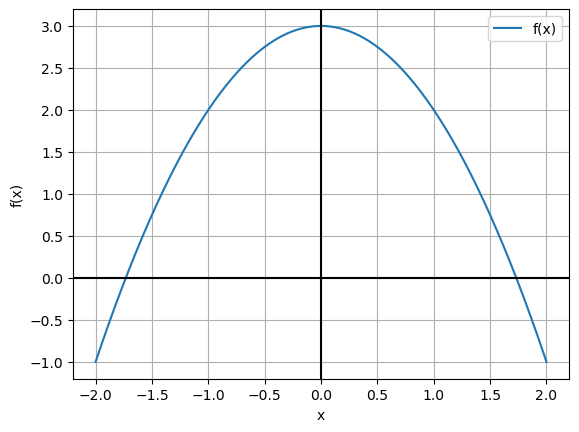

In [5]:
x = np.linspace(-2, 2, 401)  # 401 points between 0 and 3
plt.plot(x, f1(x))
plt.legend(['f(x)', '$\\tau$'])
plt.axhline(0, color='k', linewidth=1.5)  # x-axis
plt.axvline(0, color='k', linewidth=1.5)  # y-axis
plt.xlabel("x"), plt.ylabel("f(x)")
plt.grid(True)

This funciton breaks the condition: for $f(x)$ in $[-2, 2]$, $f(a)f(b)>0$, i.e. $f(a)f(b)$ have the same sign.  
Just becuase they are on teh same side of the axis, doesn;t meant he funciton can't cross it, just means it has to cross back.  
If there is _only_ one $\tau$, then the condition is necessary; if there are multiple $\tau$ then it's not.

## 1.2 Interval Bisection
a.k.a. "The Bisection Method".  
For a function satisfying the conditions of Theorem 1.1.1:  
* Set $x_2$ to be the midpoint of interval $[x_0, x_2]$
* Choose whichever sub-interval $[x_0, x_2]$ or $[x_2, x_1]$ where $f$ changes sign
* Repeat on sub-intervals
  
Because we are reducing the solution space by a factor of 2 with every step k (i.e. scale by $(\frac{1}{2})^k$), then as $k \to \infty$, solution space $2^{-k}\to0 \implies$ convergence.

In [33]:
def bisection(f, a, b, eps=10**(-10), K=None):
    true_soln = root_scalar(f, bracket=[a, b], xtol=1e-15).root
    x_k_all = [a, b]
    if K != None:
        eps = 10**(-30)
    if abs(f(a)) <= eps:
        x_k_all = [a]
    elif abs(f(b)) <= eps:
        x_k_all = [a, b]
    else:
        x_L, x_R = a, b
        k = 2
        cont = True
        while cont:
            x_k = (x_L + x_R)/2
            x_k_all.append(x_k)
            if f(x_L)*f(x_k) < 0:
                x_R = x_k
            else:
                x_L = x_k
            if abs(f(x_k)) <= eps:
                cont = False
            else:
                k += 1
                if K != None and k >= K:
                    cont = False

    x = np.linspace(a, b, 401)
    plt.plot(x, f(x))
    plt.plot(x_k_all, [0]*(len(x_k_all)), "^", color = "gray")
    plt.plot(true_soln, [0], "^", color = "r")
    plt.legend(['f(x)', '$x_k$','$\\tau$'])
    plt.axhline(0, color='k', linewidth=1.5)  # x-axis
    plt.axvline(0, color='k', linewidth=1.5)  # y-axis
    plt.xlabel("x"), plt.ylabel("f(x)")
    plt.xlim(a,b)
    plt.grid(True)
    plt.show()

    k_all = range(k+2)
    fxk_all = [abs(f(xk)) for xk in x_k_all]
    err_bound = [abs(true_soln - xk) for xk in x_k_all]
    display(Latex(rf"$\tau = {true_soln:.6f}$"))

    df = pd.DataFrame(zip(k_all, x_k_all, fxk_all, err_bound), columns = ["k", "x_k", "|f(x_k)|", "|tau - x_k|"])
    print(df.to_string(index = False))

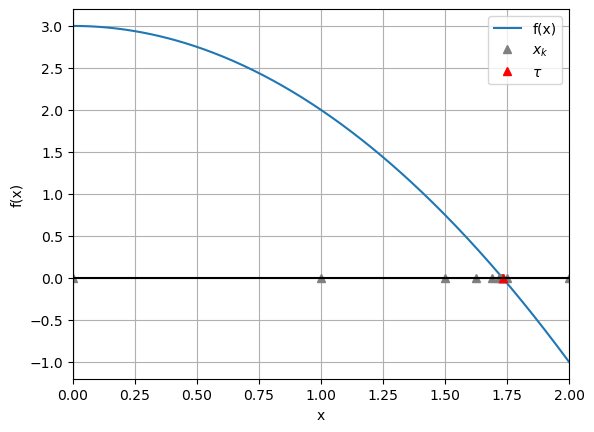

<IPython.core.display.Latex object>

 k      x_k  |f(x_k)|  |tau - x_k|
 0 0.000000  3.000000     1.732051
 1 2.000000  1.000000     0.267949
 2 1.000000  2.000000     0.732051
 3 1.500000  0.750000     0.232051
 4 1.750000  0.062500     0.017949
 5 1.625000  0.359375     0.107051
 6 1.687500  0.152344     0.044551
 7 1.718750  0.045898     0.013301
 8 1.734375  0.008057     0.002324
 9 1.726562  0.018982     0.005488
10 1.730469  0.005478     0.001582
11 1.732422  0.001286     0.000371
12 1.731445  0.002097     0.000605
13 1.731934  0.000406     0.000117


In [23]:
bisection(f1, 0, 2, 0.001)

In [9]:
def f2(x):
    return x**2 - 2

\tau =  1.4140625
k =  9


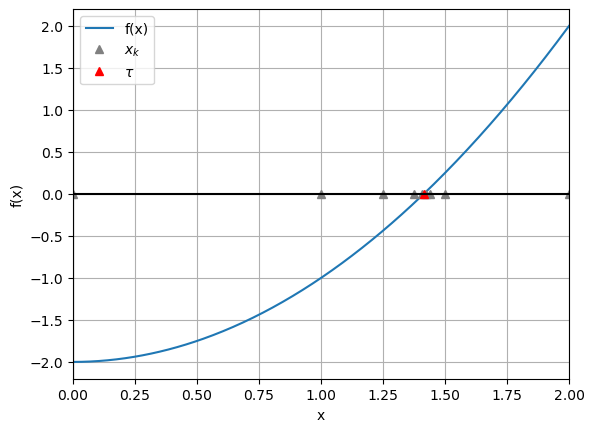

 k      x_k  |f(x_k)|  |tau - x_k|
 0 0.000000  2.000000     1.414214
 1 2.000000  2.000000     0.585786
 2 1.000000  1.000000     0.414214
 3 1.500000  0.250000     0.085786
 4 1.250000  0.437500     0.164214
 5 1.375000  0.109375     0.039214
 6 1.437500  0.066406     0.023286
 7 1.406250  0.022461     0.007964
 8 1.421875  0.021729     0.007661
 9 1.414062  0.000427     0.000151


In [ ]:
bisection(f2, 0, 2, 0.001)

### Theorem 1.2.1
Let $x_k$ be the $k$th iteration generated by the Bisection Method. Then:
$$ |\tau = x_0| \leq (\frac{1}{2})^{k-1}|b-a| \text{ , for } k = 2, 3, 4, ... $$

### Exercise 1.2.3
Let f (x) = e^x − 2x − 2. Show that there is a solution to the
problem: find τ ∈ [0, 2] such that f (τ ) = 0.
Taking x0 = 0 and x1 = 2, use 6 steps of the bisection method
to estimate τ . You may use a computer program to do this,
but please note that in your solution.
Give an upper bound for the error |τ − x6|.

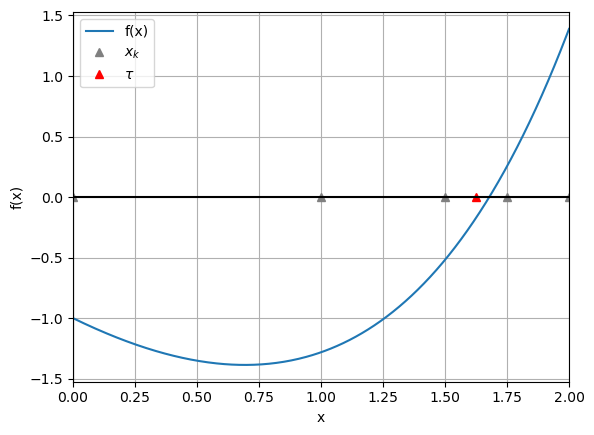

<IPython.core.display.Latex object>

 k   x_k  |f(x_k)|  |tau - x_k|
 0 0.000  1.000000     1.678347
 1 2.000  1.389056     0.321653
 2 1.000  1.281718     0.678347
 3 1.500  0.518311     0.178347
 4 1.750  0.254603     0.071653
 5 1.625  0.171581     0.053347


In [26]:
def f3(x):
    return np.exp(x)-2*x-2
bisection(f3, 0, 2, K=6)

## 1.3 The Secant Method
Instead of bisecting the separation between $x_0$ and $x_1$, take $x_2$ to be the zero of the line joining the points $(x_0, f(x_0)), (x_1,f(x_1))$; then take $x_3$ to be the zero of the line joining the points $(x_1, f(x_1)), (x_2,f(x_2))$
  
Formally: choose $x_0, x_1$ sucht that there is a solution in $[x_0,x_1]$, then define:
$$ x_{k+1} = x_k-f(x_k)\frac{x_k-x_{k-1}}{f(x_k)-f(x_{k-1})} \text{ , for }k = 1,2,3,..$$

In [35]:
def secant(f, a, b, eps=10**(-10), K=None):
    true_soln = root_scalar(f, bracket=[a, b], xtol=1e-15).root
    x_k_all = [a, b]
    if K != None:
        eps = 10**(-30)
    if abs(f(a)) <= eps:
        x_k_all = [a]
    elif abs(f(b)) <= eps:
        x_k_all = [a, b]
    else:
        x_k0, x_k1 = a, b
        k = 2
        cont = True
        while cont:
            x_k2 = x_k1 - f(x_k1)*(x_k1-x_k0)/(f(x_k1)-f(x_k0))
            x_k_all.append(x_k2)
            x_k0 = x_k1
            x_k1 = x_k2
            if abs(f(x_k2)) <= eps:
                cont = False
            else:
                k += 1
                if K != None and k >= K:
                    cont = False

    x = np.linspace(a, b, 401)
    plt.plot(x, f(x))
    plt.plot(x_k_all, [0]*(len(x_k_all)), "^", color = "gray")
    plt.plot(true_soln, [0], "^", color = "r")
    plt.legend(['f(x)', '$x_k$','$\\tau$'])
    for i in range(1,len(x_k_all)):
            xa, xb = x_k_all[i-1], x_k_all[i]
            fa, fb = f(xa), f(xb)
            xn = xb - fb * (xb - xa) / (fb - fa)
            plt.plot([xa, xb, xn], [fa, fb, 0], "--", color="gray", alpha = 0.8)
    plt.axhline(0, color='k', linewidth=1.5)  # x-axis
    plt.axvline(0, color='k', linewidth=1.5)  # y-axis
    plt.xlabel("x"), plt.ylabel("f(x)")
    plt.xlim(a,b)
    plt.grid(True)
    plt.show()

    k_all = range(k+2)
    fxk_all = [abs(f(xk)) for xk in x_k_all]
    err_bound = [abs(true_soln - xk) for xk in x_k_all]
    display(Latex(rf"$\tau = {true_soln:.6f}$"))

    df = pd.DataFrame(zip(k_all, x_k_all, fxk_all, err_bound), columns = ["k", "x_k", "|f(x_k)|", "|tau - x_k|"])
    print(df.to_string(index = False))

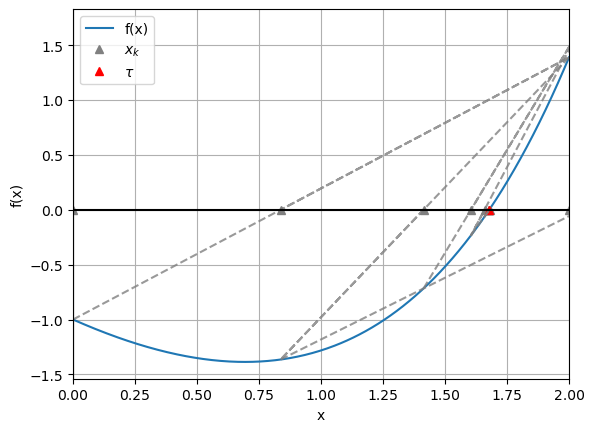

<IPython.core.display.Latex object>

 k      x_k     |f(x_k)|  |tau - x_k|
 0 0.000000 1.000000e+00 1.678347e+00
 1 2.000000 1.389056e+00 3.216530e-01
 2 0.837151 1.364525e+00 8.411963e-01
 3 1.413396 7.169040e-01 2.649514e-01
 4 2.051287 1.675334e+00 3.729405e-01
 5 1.604559 2.334545e-01 7.378845e-02
 6 1.659196 6.330870e-02 1.915122e-02
 7 1.679525 3.959476e-03 1.178468e-03
 8 1.678329 6.095516e-05 1.815955e-05
 9 1.678347 5.728692e-08 1.706647e-08
10 1.678347 8.295586e-13 2.471356e-13


In [36]:
secant(f3,0,2)